#### Import relevant libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import mahalanobis
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

#### Load dataset and subset columns

In [2]:
houseprice_data = pd.read_csv("data/HousingPricesData.csv")

In [3]:
houseprice_data = houseprice_data[['Price', 'Area', 'Room','Lon','Lat']]

#### Inspect first 5 rows and data types of the dataset

In [4]:
houseprice_data.head()

,Price,Area,Room,Lon,Lat
0,685000.0,64,3,4.907736,52.356157
1,475000.0,60,3,4.850476,52.348586
2,850000.0,109,4,4.944774,52.343782
3,580000.0,128,6,4.789928,52.343712
4,720000.0,138,5,4.902503,52.410538


In [5]:
houseprice_data.shape

(924, 5)

#### Scale the data

In [6]:
scaler = StandardScaler()
 
houseprice_data_scaled = scaler.fit_transform(houseprice_data)
houseprice_data_scaled = pd.DataFrame(houseprice_data_scaled, columns=houseprice_data.columns)
houseprice_data_scaled.head()

,Price,Area,Room,Lon,Lat
0,0.116827,-0.556503,-0.359057,0.360200,-0.298517
1,-0.273000,-0.626170,-0.359057,-0.717912,-0.613774
2,0.423119,0.227246,0.269293,1.057565,-0.813814
3,-0.078087,0.558162,1.525993,-1.857931,-0.816729
4,0.181798,0.732328,0.897643,0.261671,1.965916


#### Calculate the Mahalanobis Distance

In [7]:
# calculate the mean and covariance matrix of the dataset
mean = houseprice_data_scaled.mean()
cov = houseprice_data_scaled.cov()

# Calculate the inverse of the covariance matrix
inv_cov = np.linalg.inv(cov)

In [8]:
# Calculate the Mahalanobis distance for each observation
distances = []
for _, x in houseprice_data_scaled.iterrows():
    d = mahalanobis(x, mean, inv_cov)
    distances.append(d)

# Add the distances as a new column in the DataFrame
houseprice_data['mahalanobis_distances'] = distances

Text(0.5, 1.0, 'Outlier Analysis of Mahalanobis Distances')

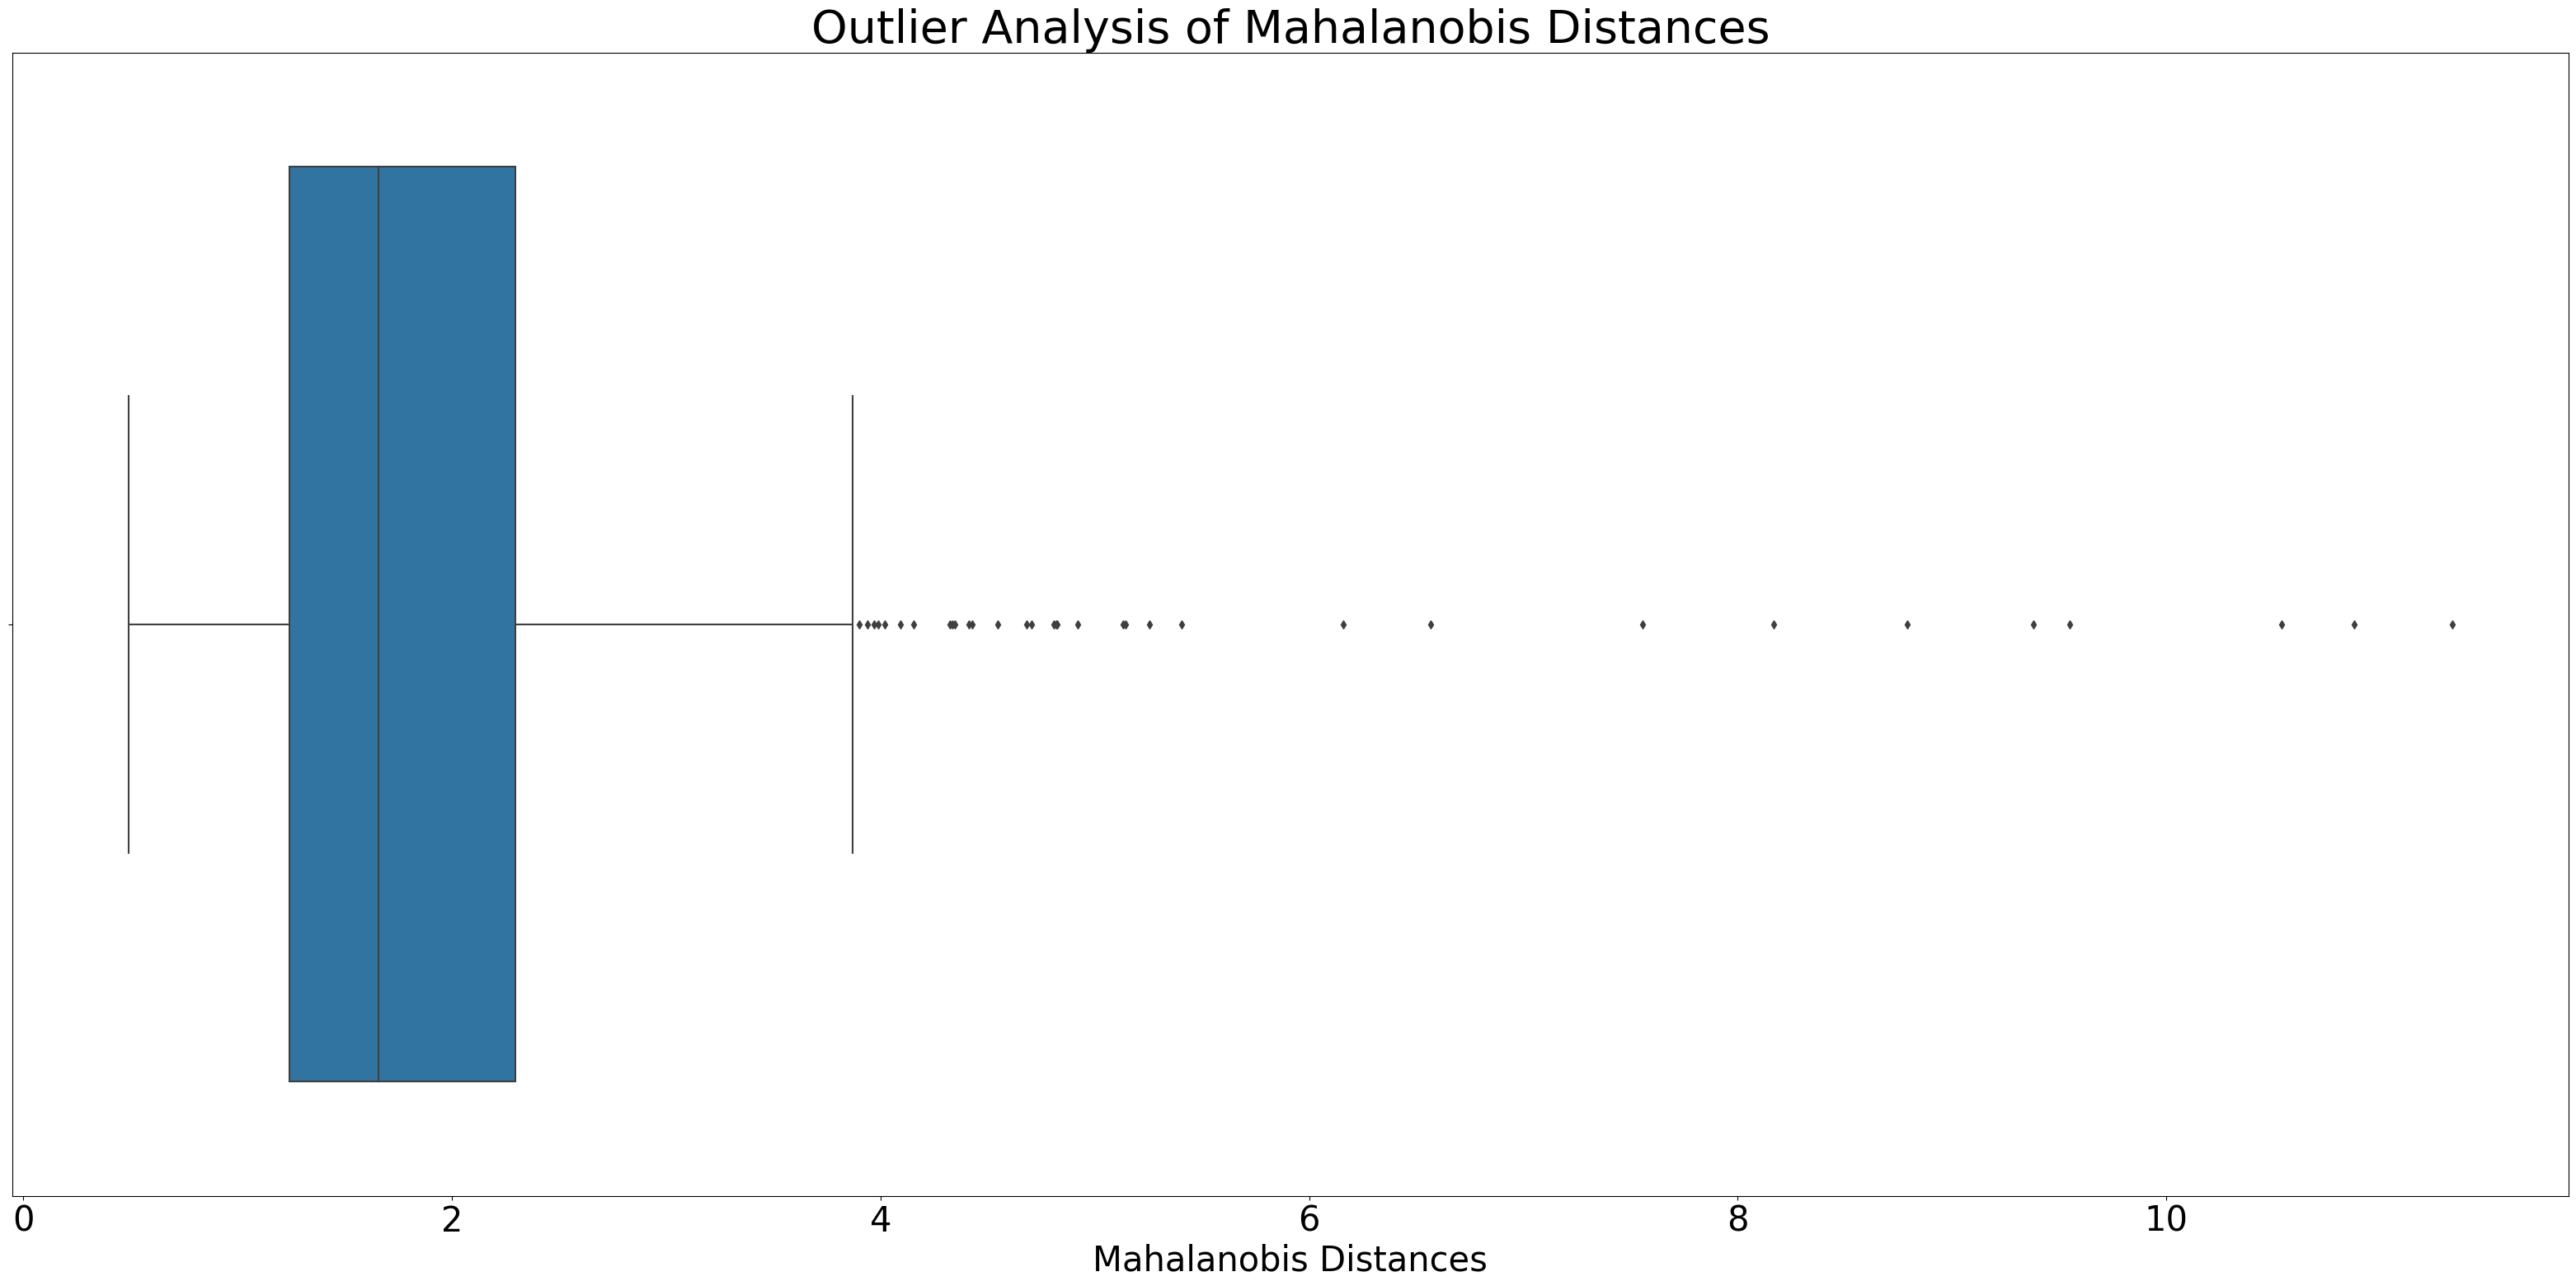

In [9]:
plt.figure(figsize = (40,18))

ax = sns.boxplot(data= houseprice_data, x= 'mahalanobis_distances')
ax.set_xlabel('Mahalanobis Distances',  fontsize = 30)
plt.xticks(fontsize=30)
ax.set_title('Outlier Analysis of Mahalanobis Distances', fontsize = 40)

In [10]:
mahalanobis_outliers = houseprice_data[houseprice_data['mahalanobis_distances']>=4]
mahalanobis_outliers.head()

,Price,Area,Room,Lon,Lat,mahalanobis_distances
31,1950000.0,258,4,4.887444,52.385346,4.547578
33,3925000.0,319,7,4.875471,52.361571,6.566091
103,4550000.0,497,13,4.898620,52.358798,7.558049
156,799000.0,230,8,4.961381,52.389087,4.346119
179,4495000.0,178,5,4.894290,52.373106,10.876237


In [11]:
houseprice_data_no_missing = houseprice_data_scaled.dropna()

#### Perform DBSCAN

In [12]:
knn = NearestNeighbors(n_neighbors=2)
nbrs = knn.fit(houseprice_data_no_missing)
distances, indices = nbrs.kneighbors(houseprice_data_no_missing)

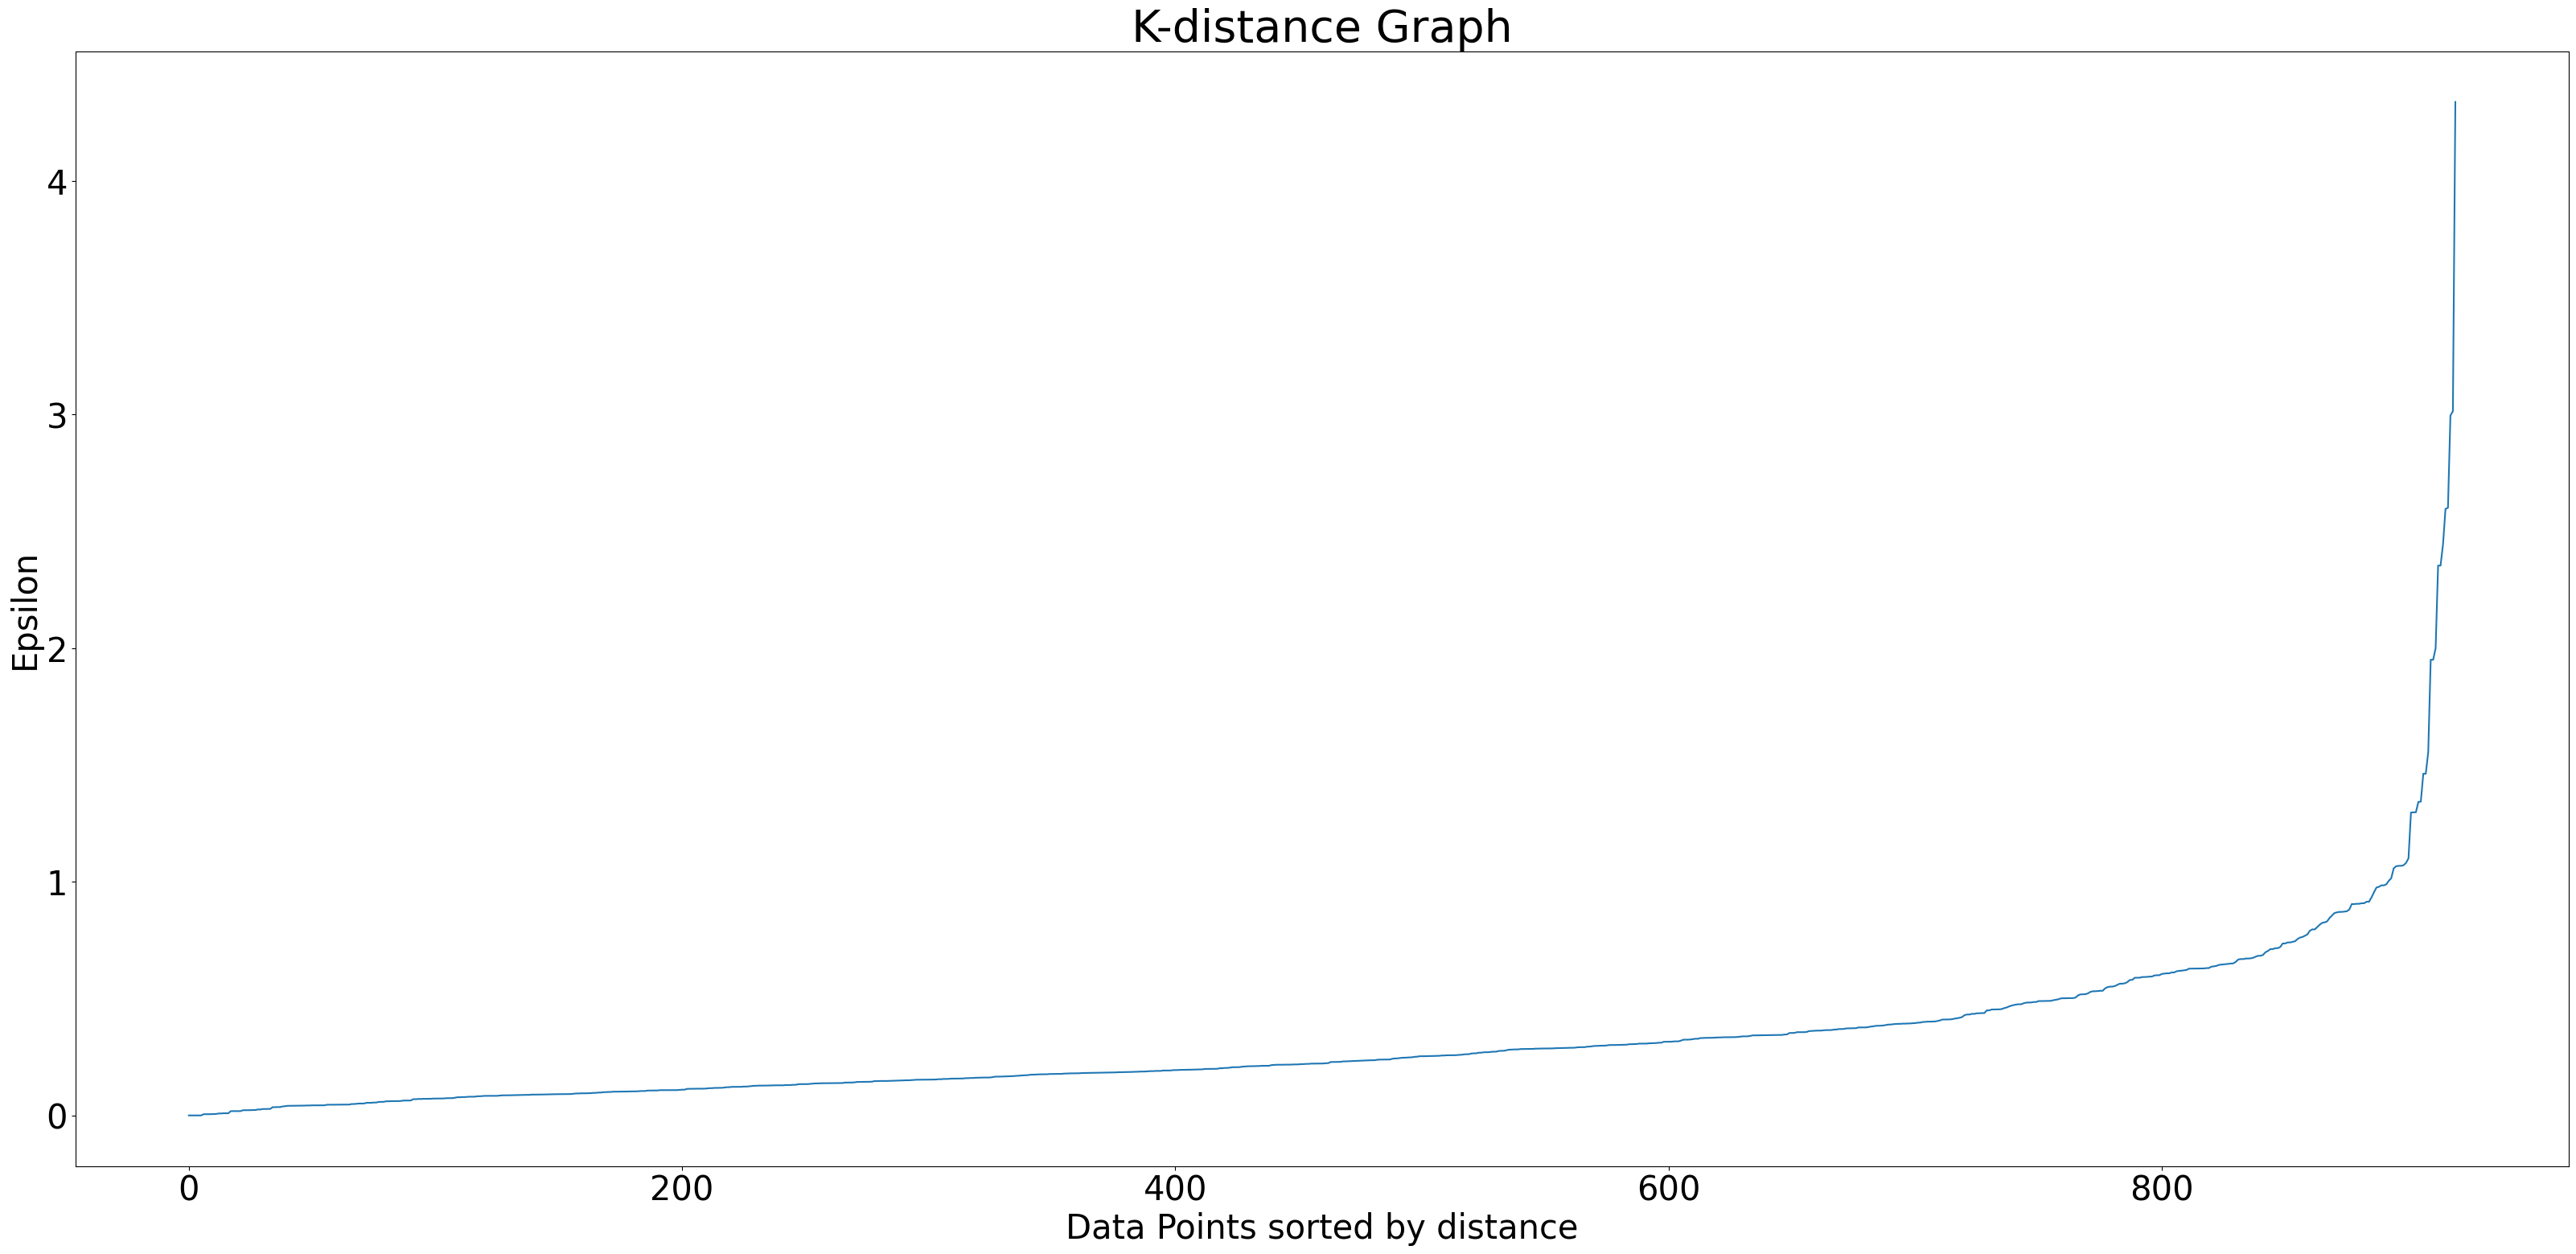

In [13]:
# Plotting K-distance Graph
distances = np.sort(distances, axis=0)
distances = distances[:,1]
plt.figure(figsize=(40,18))
plt.plot(distances)
plt.title('K-distance Graph',fontsize=40)
plt.xlabel('Data Points sorted by distance',fontsize=30)
plt.ylabel('Epsilon',fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.show()

In [14]:
# Create a DBSCAN object and fit the data
dbscan = DBSCAN(eps= 1, min_samples=6)
dbscan.fit(houseprice_data_no_missing)

# Get the labels and number of clusters
labels = dbscan.labels_
n_clusters = len(set(labels)) 
outlier_indices = np.where(labels == -1)[0]

# Print the number of clusters and outliers
print(f"Number of clusters: {n_clusters}")
print(f"Number of outliers: {len(outlier_indices)}")

Number of clusters: 2
Number of outliers: 57


In [15]:
houseprice_data.loc[outlier_indices,:].head()

,Price,Area,Room,Lon,Lat,mahalanobis_distances
28,1650000.0,235,7,4.820848,52.358631,2.802948
31,1950000.0,258,4,4.887444,52.385346,4.547578
33,3925000.0,319,7,4.875471,52.361571,6.566091
87,995000.0,97,2,4.884982,52.369202,1.956290
102,725000.0,95,3,4.886006,52.377377,0.842156


Text(0.5, 1.0, 'Outlier Analysis of Mahalanobis Distances')

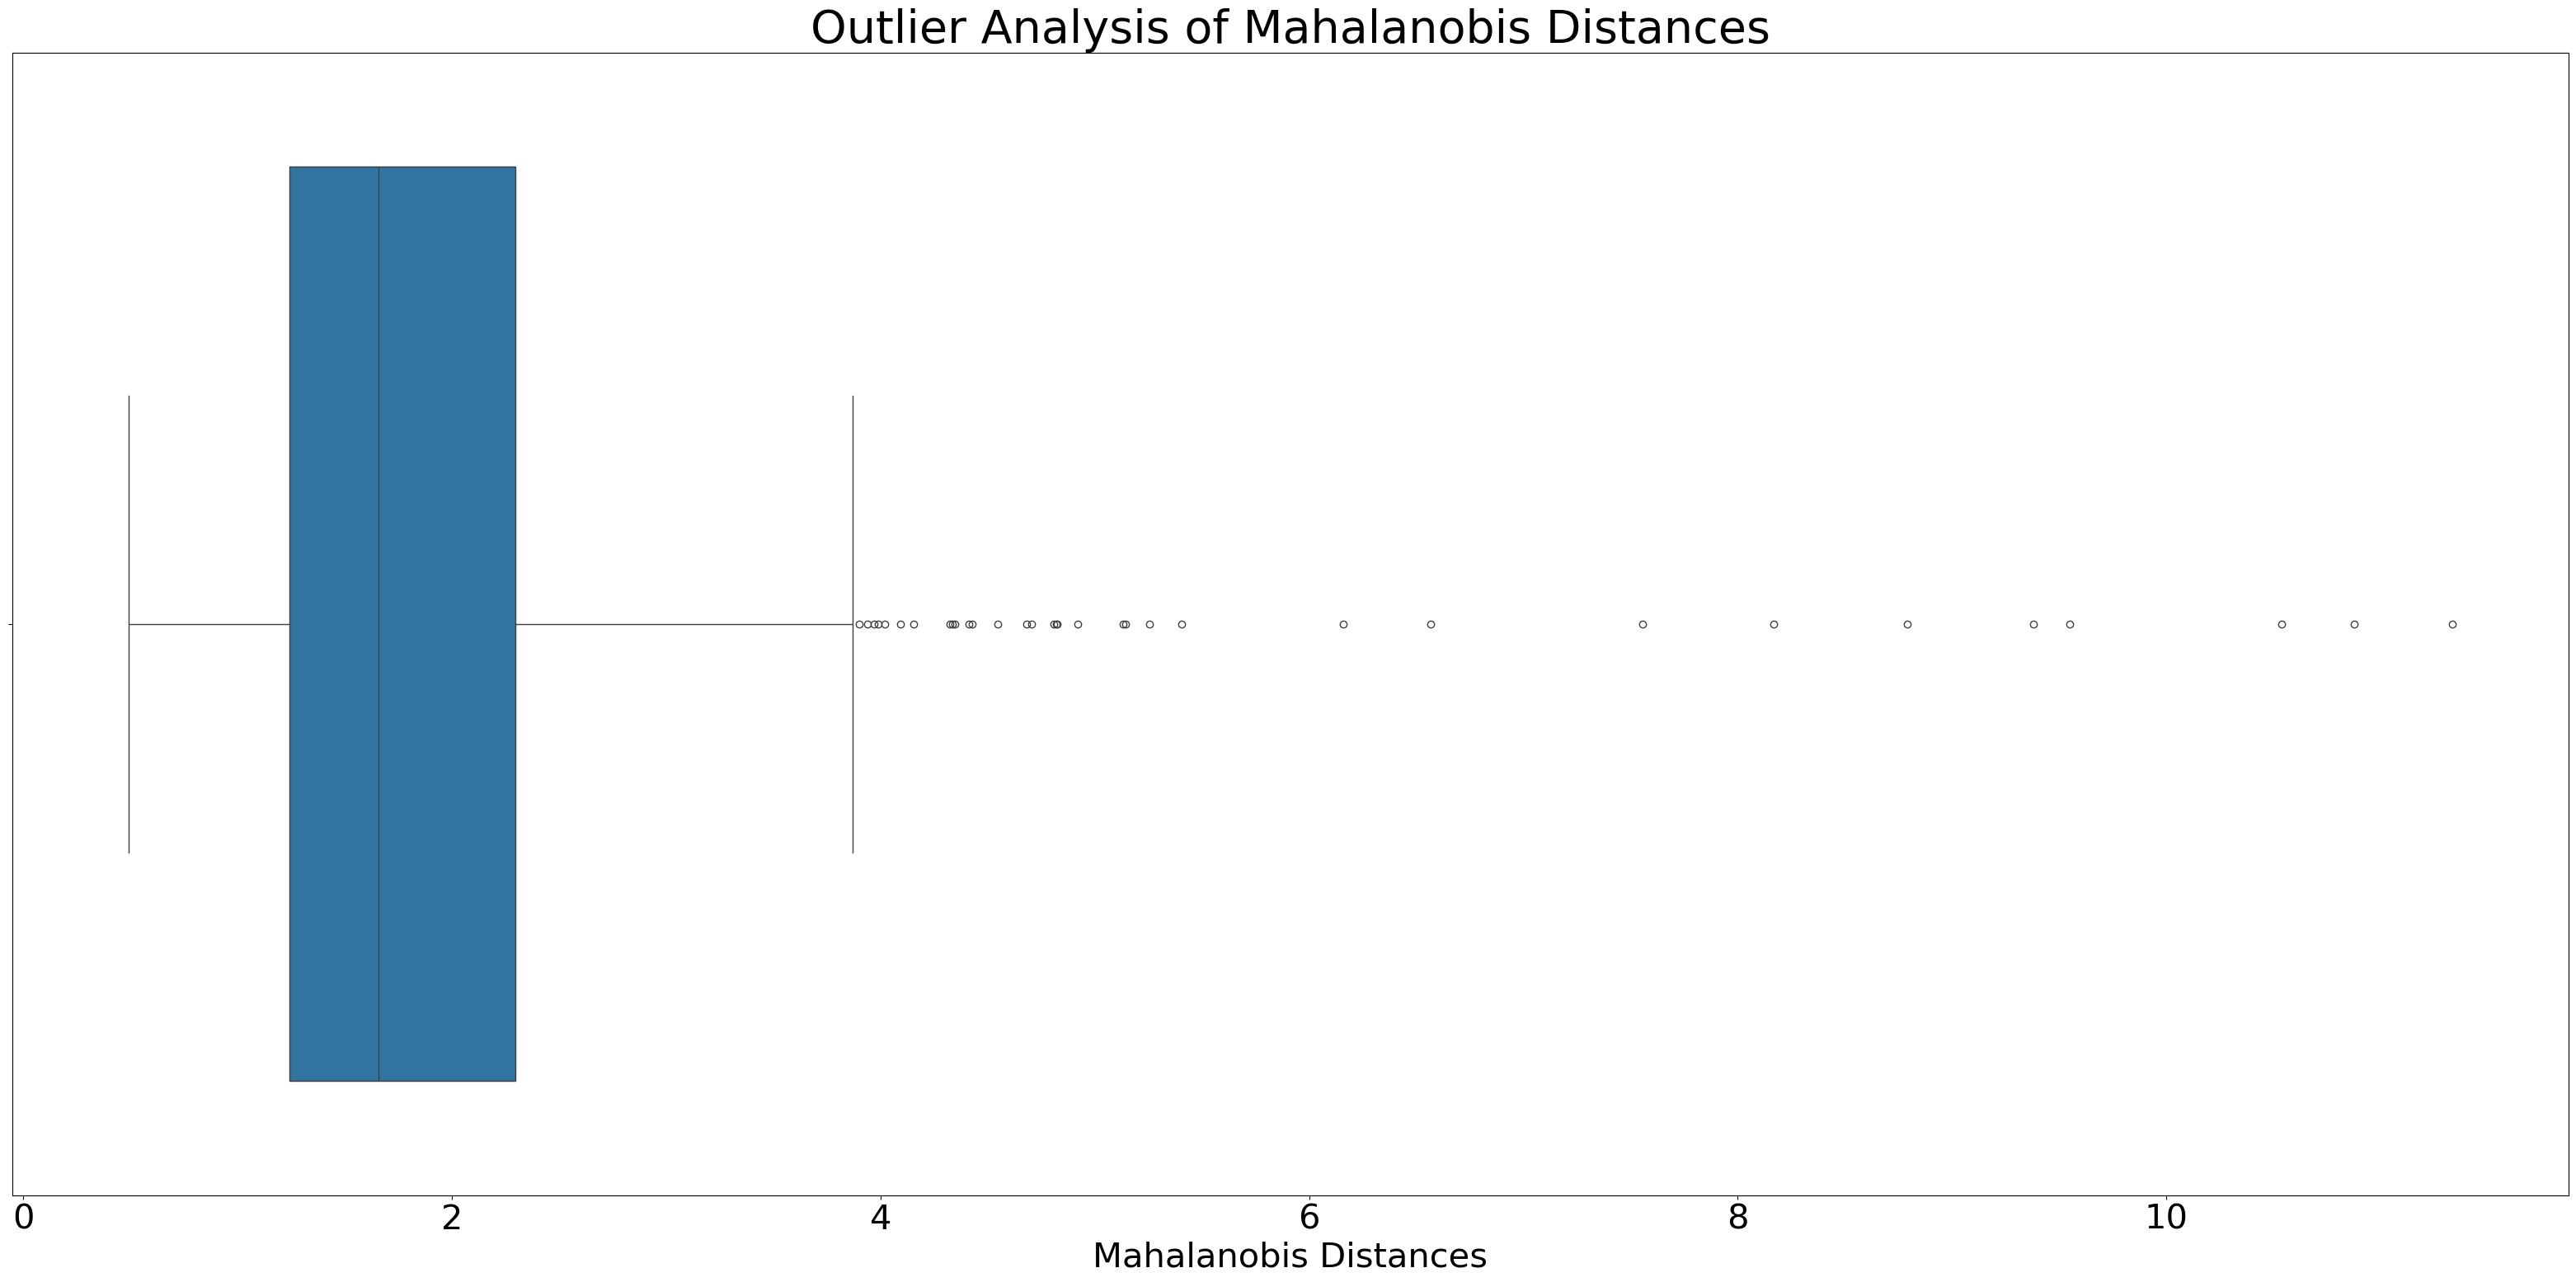

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import mahalanobis

# calculate all Mahalanobis distances instantly without any loops by using vectorized NumPy matrix operations
houseprice_data = pd.read_csv("data/HousingPricesData.csv")
houseprice_data = houseprice_data[['Price', 'Area', 'Room','Lon','Lat']]
scaler = StandardScaler()
houseprice_data_scaled = scaler.fit_transform(houseprice_data)
houseprice_data_scaled = pd.DataFrame(houseprice_data_scaled, columns=houseprice_data.columns)
mean = houseprice_data_scaled.mean()
cov = houseprice_data_scaled.cov()
inv_cov = np.linalg.inv(cov)

# 1. Convert your scaled dataframe to a raw NumPy matrix
X = houseprice_data_scaled.values

# 2. Compute the difference vector for all rows simultaneously
diff = X - mean.values

# 3. Calculate Mahalanobis distances for all rows in a single vectorized step
# This replaces your entire row-by-row loop instantly
distances = np.sqrt(np.sum(np.dot(diff, inv_cov) * diff, axis=1))

# 4. Convert back to a list or assign it directly as a new column
houseprice_data_scaled['mahalanobis_distances'] = distances

plt.figure(figsize = (40,18))
ax = sns.boxplot(data= houseprice_data_scaled, x= 'mahalanobis_distances')
ax.set_xlabel('Mahalanobis Distances',  fontsize = 30)
plt.xticks(fontsize=30)
ax.set_title('Outlier Analysis of Mahalanobis Distances', fontsize = 40)

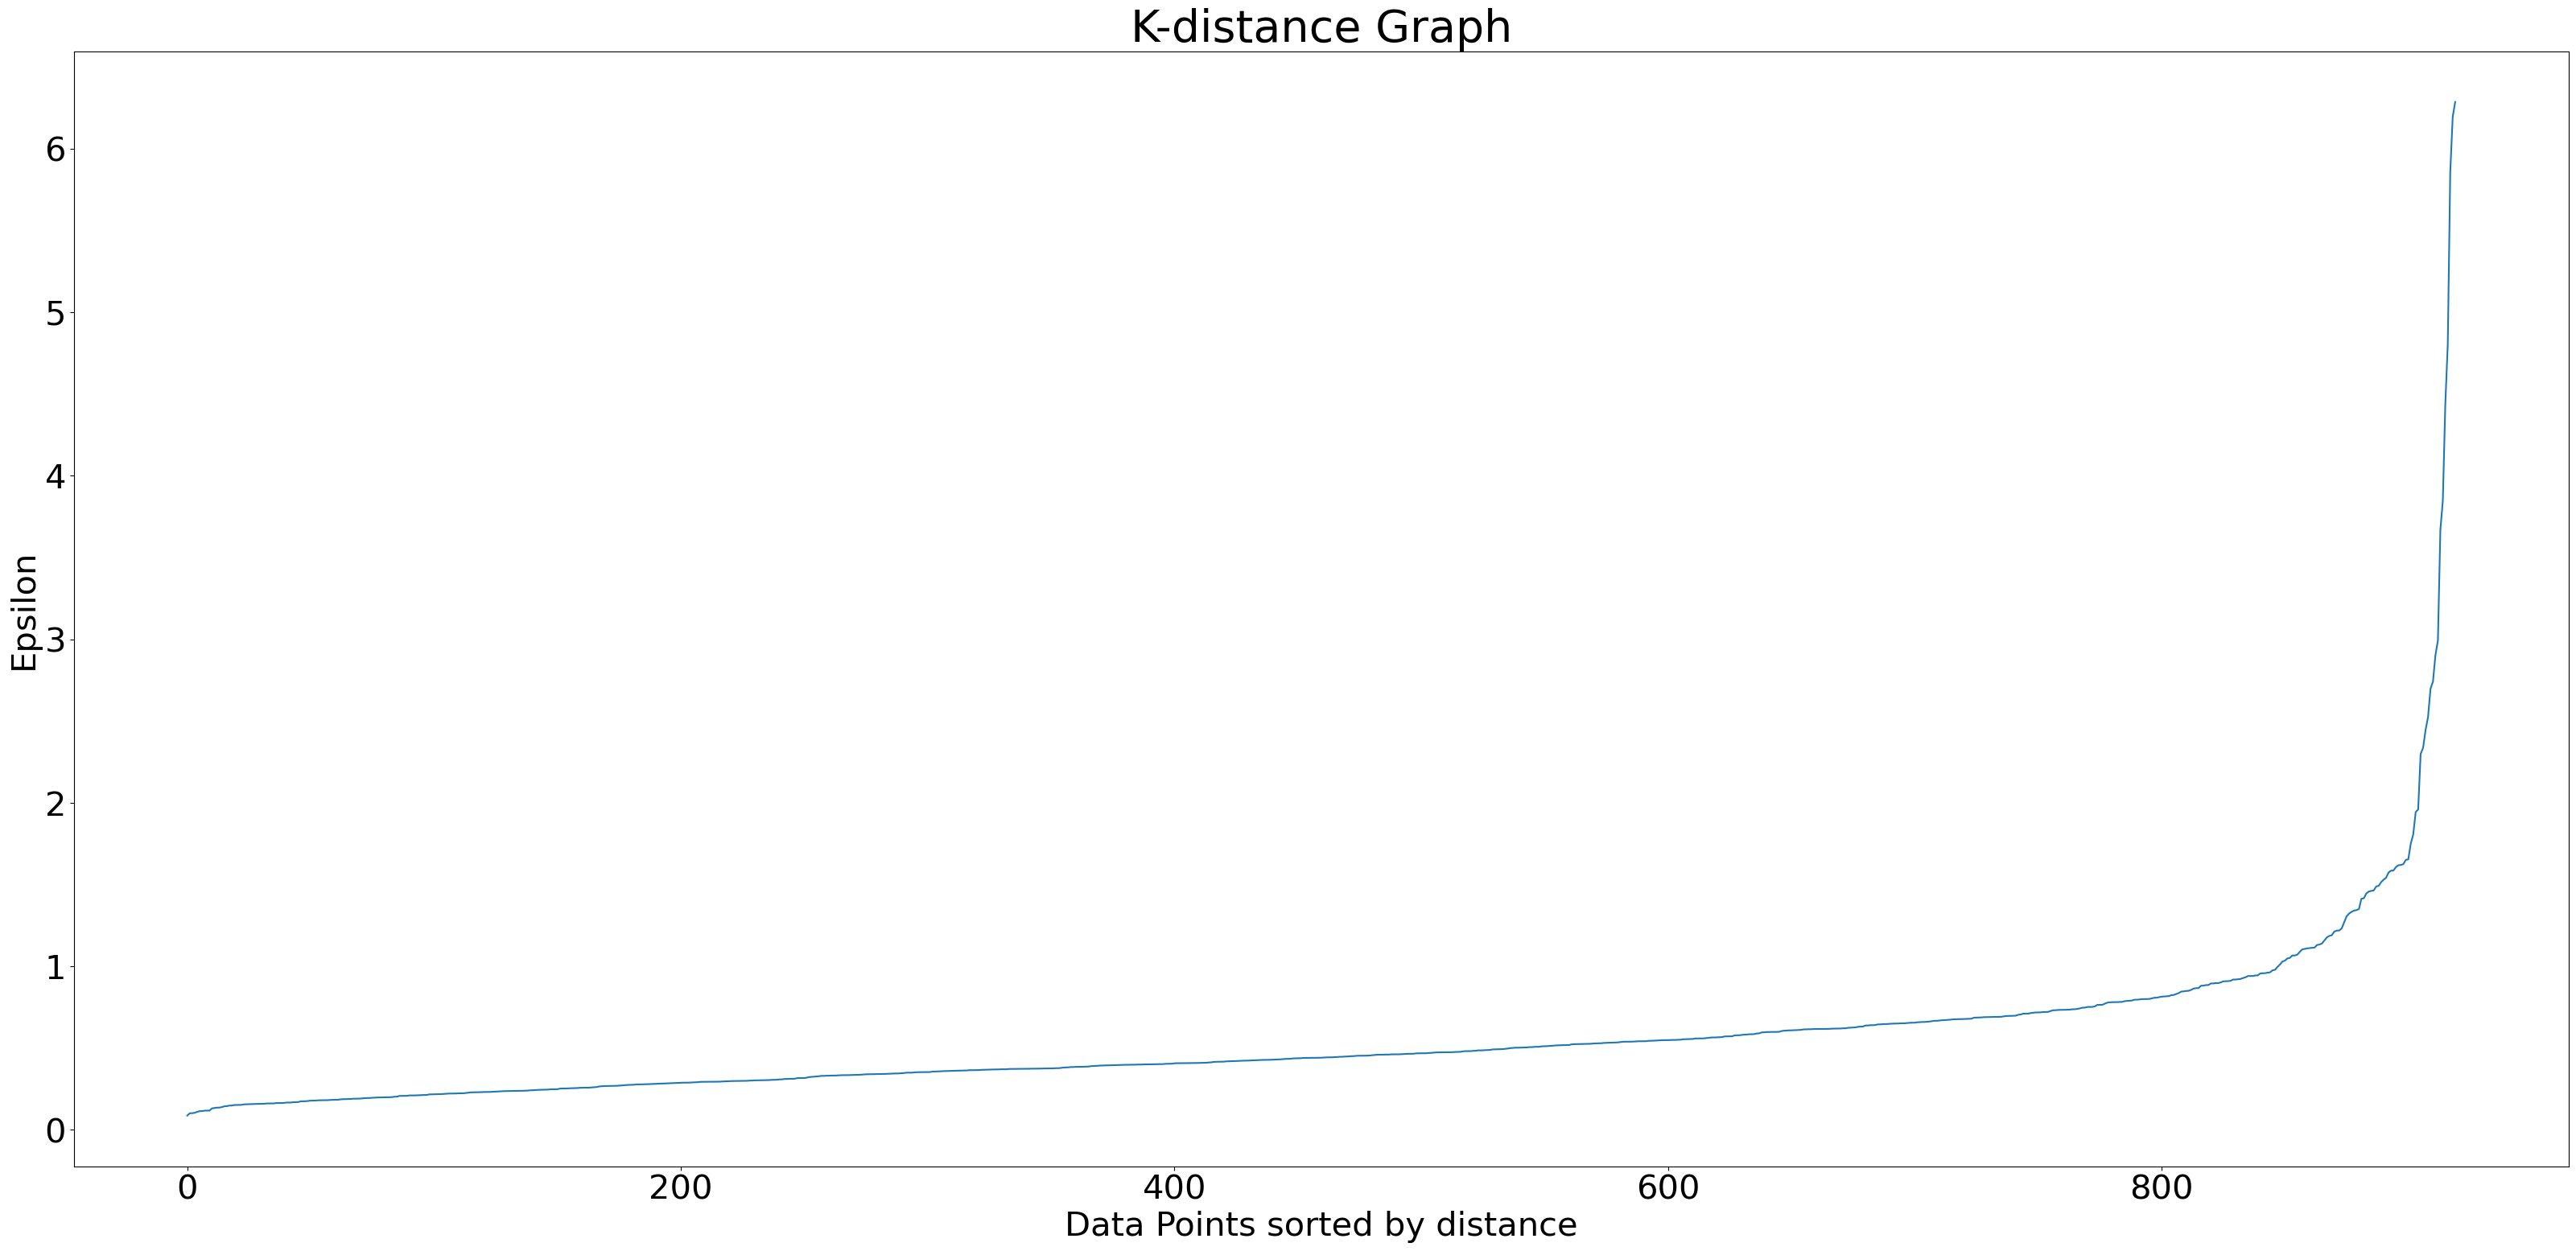

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

houseprice_data = pd.read_csv("data/HousingPricesData.csv")
houseprice_data = houseprice_data[['Price', 'Area', 'Room','Lon','Lat']]
scaler = StandardScaler()
houseprice_data_scaled = scaler.fit_transform(houseprice_data)
houseprice_data_scaled = pd.DataFrame(houseprice_data_scaled, columns=houseprice_data.columns)

houseprice_data_no_missing = houseprice_data_scaled.dropna()
knn = NearestNeighbors(n_neighbors=5)
nbrs = knn.fit(houseprice_data_no_missing)
distances, indices = nbrs.kneighbors(houseprice_data_no_missing)
# Plotting K-distance Graph
distances = np.sort(distances, axis=0)
distances = distances[:,4]
plt.figure(figsize=(40,18))
plt.plot(distances)
plt.title('K-distance Graph',fontsize=40)
plt.xlabel('Data Points sorted by distance',fontsize=30)
plt.ylabel('Epsilon',fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.show()

In [7]:
# Create a DBSCAN object and fit the data
dbscan = DBSCAN(eps= 1.5, min_samples=5)
dbscan.fit(houseprice_data_no_missing)

# Get the labels and number of clusters
labels = dbscan.labels_
n_clusters = len(set(labels)) 
outlier_indices = np.where(labels == -1)[0]

# Print the number of clusters and outliers
print(f"Number of clusters: {n_clusters}")
print(f"Number of outliers: {len(outlier_indices)}")

Number of clusters: 2
Number of outliers: 19
